<a href="https://colab.research.google.com/github/Konoplyai/pattern-recognition-practice/blob/model-comparison/classification-mini-project/notebooks/PR04_Konoplia_I.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практичні роботи 4-7

## Мініпроєкт "Порівняння класичних моделей класифікації"

**Дисципліна:** Розпізнавання образів і машинне навчання<br>
**Студент:** Конопля Іван<br>
**Група:** ІН-42/1<br>
**Дата виконання:** 24.11.2026

### Мета роботи

Навчитися будувати відтворюваний конвеєр машинного навчання, застосовувати
класичні алгоритми класифікації, налаштовувати їхні основні гіперпараметри
та коректно порівнювати моделі за однаковими умовами без використання
тестової вибірки для підбору рішень.

## Постановка задачі

- **Об'єкт дослідження:** пацієнти, для яких виміряно клінічні показники (набір Heart Disease, Cleveland, UCI).
- **Ознаки:** 13 вхідних ознак: 5 числових (age, trestbps, chol, thalach, oldpeak) і 8 категоріальних, закодованих числами (sex, cp, fbs, restecg, exang, slope, ca, thal).
- **Цільова змінна:** `target` (0 - ознаки серцевого захворювання відсутні, 1 - ознаки наявні).
- **Кількість класів:** 2, задача бінарної класифікації з навчанням за розміченими даними.
- **Позитивний клас:** 1 (наявність ознак захворювання). Для нього обчислюються precision, recall і F1.
- **Практична мета:** за характеристиками пацієнта визначити, чи належить він до класу з наявністю ознак серцевого захворювання.
- **Основна метрика (обрана до експериментів):** CV F1 для класу 1. Додаткові метрики: CV ROC AUC і CV Recall, бо пропуск хворого пацієнта небезпечніший за хибну тривогу.
- **Правило вибору фінальної моделі:** найбільший середній CV F1; якщо різниця між кандидатами менша за 0.01, перевага надається моделі з меншим стандартним відхиленням F1, а далі простішій та інтерпретованішій.

**Етичне застереження.** Результати цього навчального мініпроєкту не є медичним діагнозом і не повинні використовуватися для клінічних рішень.

# ЧАСТИНА I. ПРАКТИЧНА РОБОТА 4
## Підготовка даних, Pipeline і логістична регресія

### 1. Підключення бібліотек і загальні налаштування

In [1]:
import time
import shutil
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_predict,
    GridSearchCV
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display

RANDOM_STATE = 42
POSITIVE_CLASS = 1
PRIMARY_METRIC = "f1"

SKLEARN_VERSION = tuple(int(p) for p in sklearn.__version__.split(".")[:2])
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

print("scikit-learn:", sklearn.__version__)
print("Позитивний клас:", POSITIVE_CLASS)
print("Основна метрика:", PRIMARY_METRIC)

scikit-learn: 1.6.1
Позитивний клас: 1
Основна метрика: f1


In [2]:
PROJECT_DIR = Path("classification-mini-project")

DATA_URL = (
    "https://raw.githubusercontent.com/Konoplyai/"
    "pattern-recognition-practice/model-comparison/"
    "classification-mini-project/data/heart_disease.csv"
)
LOCAL_DATA_PATH = PROJECT_DIR / "data" / "heart_disease.csv"

MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODELS_DIR / "best_classifier.joblib"
CV_TABLE_PATH = REPORTS_DIR / "cv_model_comparison.csv"
TEST_METRICS_PATH = REPORTS_DIR / "final_test_metrics.csv"

DATA_SOURCE = LOCAL_DATA_PATH if LOCAL_DATA_PATH.exists() else DATA_URL
print("Джерело даних:", DATA_SOURCE)
print("Файл моделі:", MODEL_PATH)

Джерело даних: https://raw.githubusercontent.com/Konoplyai/pattern-recognition-practice/model-comparison/classification-mini-project/data/heart_disease.csv
Файл моделі: classification-mini-project/models/best_classifier.joblib


### 2. Завантаження та первинна перевірка даних

Набір отримано з UCI Machine Learning Repository (файл `processed.cleveland.data`).
Значення `?` замінено на пропуски, цільову змінну `num` перетворено на `target`:
0 залишився класом 0, значення 1-4 об'єднано в клас 1. На цьому етапі жодних
перетворень, що навчаються на даних, не виконується.

In [3]:
data = pd.read_csv(DATA_SOURCE)
display(data.head())
print("Розмір таблиці:", data.shape)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


Розмір таблиці: (303, 14)


In [4]:
print("Типи даних:")
print(data.dtypes)
print()
missing = data.isna().sum()
print("Пропущені значення за стовпцями:")
print(missing[missing > 0])
print("Усього пропусків:", int(missing.sum()))

Типи даних:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
target        int64
dtype: object

Пропущені значення за стовпцями:
ca      4
thal    2
dtype: int64
Усього пропусків: 6


In [5]:
TARGET = "target"
numeric_columns = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_columns = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

assert set(numeric_columns + categorical_columns + [TARGET]) == set(data.columns)
assert set(data[TARGET].unique()) == {0, 1}, "Недопустимі значення target"

print("Допустимі значення target:", sorted(data[TARGET].unique()))
print()
print("Розподіл класів:")
class_table = pd.DataFrame({
    "Кількість": data[TARGET].value_counts().sort_index(),
    "Частка": data[TARGET].value_counts(normalize=True).sort_index().round(3)
})
display(class_table)

Допустимі значення target: [np.int64(0), np.int64(1)]

Розподіл класів:


,Кількість,Частка
target,,
0,164,0.541
1,139,0.459


In [6]:
audit = pd.DataFrame({
    "Характеристика": [
        "Кількість об'єктів",
        "Кількість вхідних ознак",
        "Числові ознаки",
        "Категоріальні ознаки",
        "Кількість пропусків",
        "Кількість класів",
        "Позитивний клас"
    ],
    "Значення": [
        len(data),
        len(numeric_columns) + len(categorical_columns),
        ", ".join(numeric_columns),
        ", ".join(categorical_columns),
        f"{int(missing.sum())} (ca: {int(missing['ca'])}, thal: {int(missing['thal'])})",
        data[TARGET].nunique(),
        POSITIVE_CLASS
    ]
})
display(audit)

,Характеристика,Значення
0,Кількість об'єктів,303
1,Кількість вхідних ознак,13
2,Числові ознаки,"age, trestbps, chol, thalach, oldpeak"
3,Категоріальні ознаки,"sex, cp, fbs, restecg, exang, slope, ca, thal"
4,Кількість пропусків,"6 (ca: 4, thal: 2)"
5,Кількість класів,2
6,Позитивний клас,1


Частина категоріальних ознак збережена числовими кодами (наприклад, `cp` = 1, 2, 3, 4).
Тип `int` або `float` у pandas не означає, що ознака кількісна, тому такі
стовпці обробляються як категоріальні за допомогою OneHotEncoder, а
StandardScaler застосовується лише до 5 числових ознак.

### 3. Виділення X і y та одноразовий стратифікований поділ 80/20

In [7]:
X = data.drop(columns=TARGET)
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

split_table = pd.DataFrame({
    "Вибірка": ["Весь набір", "Train", "Test"],
    "Об'єктів": [len(y), len(y_train), len(y_test)],
    "Частка класу 1": [y.mean(), y_train.mean(), y_test.mean()]
}).round(3)
display(split_table)
print("X_test і y_test далі не використовуються до практичної роботи 7.")

,Вибірка,Об'єктів,Частка класу 1
0,Весь набір,303,0.459
1,Train,242,0.459
2,Test,61,0.459


X_test і y_test далі не використовуються до практичної роботи 7.


### 4. Єдина схема крос-валідації та функція оцінювання

In [8]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

SCORING = {
    "f1": "f1",
    "roc_auc": "roc_auc",
    "recall": "recall",
    "precision": "precision",
    "accuracy": "accuracy"
}


def evaluate_cv(name, pipeline, params="-"):
    """Оцінює Pipeline на X_train, y_train за єдиною схемою cv."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        res = cross_validate(
            pipeline, X_train, y_train,
            cv=cv, scoring=SCORING, error_score="raise"
        )
    n_conv = sum(issubclass(w.category, ConvergenceWarning) for w in caught)
    other = [w for w in caught
             if not issubclass(w.category, (ConvergenceWarning, FutureWarning, DeprecationWarning))]
    n_other = len(other)
    other_msgs = sorted({f"{w.category.__name__}: {str(w.message).split('.')[0]}" for w in other})
    return {
        "Модель": name,
        "Параметри": params,
        "CV F1": res["test_f1"].mean(),
        "CV F1 std": res["test_f1"].std(),
        "CV ROC AUC": res["test_roc_auc"].mean(),
        "CV ROC AUC std": res["test_roc_auc"].std(),
        "CV Recall": res["test_recall"].mean(),
        "CV Precision": res["test_precision"].mean(),
        "CV Accuracy": res["test_accuracy"].mean(),
        "Час навчання, с": res["fit_time"].mean(),
        "Час прогнозу, с": res["score_time"].mean(),
        "Попередж. збіжності": n_conv,
        "Інші попередж.": n_other,
        "Тексти попереджень": other_msgs
    }


print("Фолдів:", cv.get_n_splits())
for i, (tr, va) in enumerate(cv.split(X_train, y_train), start=1):
    print(f"Фолд {i}: train={len(tr)}, val={len(va)}, частка класу 1 у val={y_train.iloc[va].mean():.3f}")

Фолдів: 5
Фолд 1: train=193, val=49, частка класу 1 у val=0.469
Фолд 2: train=193, val=49, частка класу 1 у val=0.449
Фолд 3: train=194, val=48, частка класу 1 у val=0.458
Фолд 4: train=194, val=48, частка класу 1 у val=0.458
Фолд 5: train=194, val=48, частка класу 1 у val=0.458


### 5. ColumnTransformer і Pipeline

Числові ознаки: медіанна імпутація, потім StandardScaler (або `passthrough`
для варіанта без масштабування). Категоріальні ознаки: імпутація модою, потім
OneHotEncoder з `handle_unknown="ignore"` і щільною матрицею. Усі параметри
навчаються всередині Pipeline лише на train-частині кожного фолду.

In [9]:
def make_encoder():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:  # старі версії scikit-learn
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


def make_preprocessor(scale=True):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler() if scale else "passthrough")
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", make_encoder())
    ])
    return ColumnTransformer([
        ("num", numeric_pipeline, numeric_columns),
        ("cat", categorical_pipeline, categorical_columns)
    ])


def make_pipeline(classifier, scale=True):
    return Pipeline([
        ("preprocessor", make_preprocessor(scale)),
        ("classifier", classifier)
    ])


def make_logreg(reg="l2", C=1.0, solver="lbfgs"):
    """Логістична регресія, сумісна зі старими й новими версіями scikit-learn."""
    params = dict(C=C, solver=solver, max_iter=2000, random_state=RANDOM_STATE)
    if SKLEARN_VERSION >= (1, 8):
        params["l1_ratio"] = 1.0 if reg == "l1" else 0.0
    else:
        params["penalty"] = reg
    return LogisticRegression(**params)


demo = make_pipeline(make_logreg())
demo.fit(X_train, y_train)
n_out = demo.named_steps["preprocessor"].get_feature_names_out().shape[0]
print("Ознак після ColumnTransformer:", n_out)
demo

Ознак після ColumnTransformer: 28


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['sex', 'cp', 'fbs',
                                                   'restecg', 'exang', 'slope',
                                                   'ca', 'thal'])])),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42))])

### 6. Логістична регресія: вплив масштабування

In [10]:
pipelines_scaling = {
    "LogReg без масштабування": make_pipeline(make_logreg(), scale=False),
    "LogReg зі StandardScaler": make_pipeline(make_logreg(), scale=True)
}

rows = []
for name, pipe in pipelines_scaling.items():
    row = evaluate_cv(name, pipe, "L2, C=1, lbfgs")
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        pipe.fit(X_train, y_train)
    row["Ітерацій (весь train)"] = int(pipe.named_steps["classifier"].n_iter_[0])
    rows.append(row)

scaling_table = pd.DataFrame(rows)[[
    "Модель", "CV F1", "CV F1 std", "CV ROC AUC", "CV ROC AUC std",
    "Ітерацій (весь train)", "Попередж. збіжності"
]]
display(scaling_table.round(4))

,Модель,CV F1,CV F1 std,CV ROC AUC,CV ROC AUC std,Ітерацій (весь train),Попередж. збіжності
0,LogReg без масштабування,0.8245,0.0069,0.8997,0.0157,1238,0
1,LogReg зі StandardScaler,0.8245,0.0069,0.9025,0.0144,18,0


**Висновок щодо масштабування.** За однаковою крос-валідацією обидва варіанти
логістичної регресії дали однаковий середній CV F1 = 0.8245 (std 0.0069), а
CV ROC AUC зі StandardScaler трохи вищий (0.9025 проти 0.8997). Головна різниця
у збіжності: без масштабування оптимізатору lbfgs знадобилося 1238 ітерацій на
всій train-вибірці, а після стандартизації лише 18. Попереджень про збіжність
немає лише тому, що встановлено max_iter=2000. Отже, масштабування майже не змінює
якість, але робить навчання значно стабільнішим і швидшим, тому далі
використовується Pipeline зі StandardScaler.

### 7. L1- і L2-регуляризація для різних C

In [11]:
C_VALUES = [0.01, 0.1, 1, 10, 100]
rows = []
for reg in ["l1", "l2"]:
    for C in C_VALUES:
        pipe = make_pipeline(make_logreg(reg, C, solver="liblinear"))
        row = evaluate_cv("Logistic Regression", pipe, f"{reg.upper()}, C={C}")
        row["Регуляризація"] = reg.upper()
        row["C"] = C
        rows.append(row)

lr_grid = pd.DataFrame(rows)
display(lr_grid[[
    "Регуляризація", "C", "CV F1", "CV F1 std", "CV ROC AUC", "CV Recall"
]].round(4))

,Регуляризація,C,CV F1,CV F1 std,CV ROC AUC,CV Recall
0,L1,0.01,0.0000,0.0000,0.5000,0.0000
1,L1,0.10,0.7926,0.0306,0.8844,0.7466
2,L1,1.00,0.8123,0.0173,0.9070,0.7834
3,L1,10.00,0.8321,0.0108,0.9019,0.8016
4,L1,100.00,0.8363,0.0127,0.8974,0.8016
5,L2,0.01,0.7658,0.0171,0.8886,0.6933
6,L2,0.10,0.8140,0.0299,0.9025,0.7739
7,L2,1.00,0.8245,0.0069,0.9025,0.7834
8,L2,10.00,0.8363,0.0127,0.9002,0.8016
9,L2,100.00,0.8363,0.0127,0.8977,0.8016


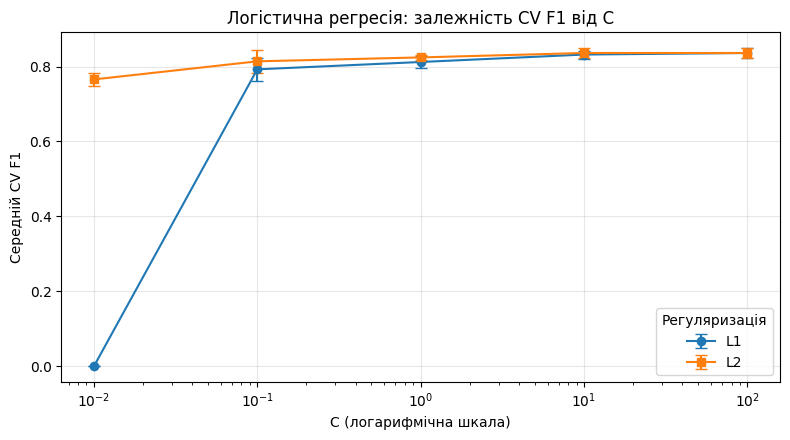

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for reg, marker in [("L1", "o"), ("L2", "s")]:
    part = lr_grid[lr_grid["Регуляризація"] == reg]
    ax.errorbar(part["C"], part["CV F1"], yerr=part["CV F1 std"],
                marker=marker, capsize=4, label=reg)
ax.set_xscale("log")
ax.set_xlabel("C (логарифмічна шкала)")
ax.set_ylabel("Середній CV F1")
ax.set_title("Логістична регресія: залежність CV F1 від C")
ax.grid(alpha=0.3)
ax.legend(title="Регуляризація")
plt.tight_layout()
plt.show()

In [13]:
best_lr_row = lr_grid.sort_values(
    ["CV F1", "CV F1 std"], ascending=[False, True]
).iloc[0]
BEST_LR_REG = best_lr_row["Регуляризація"].lower()
BEST_LR_C = float(best_lr_row["C"])
BEST_LR_C = int(BEST_LR_C) if BEST_LR_C.is_integer() else BEST_LR_C

ties = lr_grid[
    (lr_grid["CV F1"].round(4) == round(best_lr_row["CV F1"], 4))
    & (lr_grid["CV F1 std"].round(4) == round(best_lr_row["CV F1 std"], 4))
]
print("Конфігурації з однаковим найкращим CV F1 і std:")
display(ties[["Регуляризація", "C", "CV F1", "CV F1 std", "CV ROC AUC"]].round(4))

best_lr_pipeline = make_pipeline(
    make_logreg(BEST_LR_REG, BEST_LR_C, solver="liblinear")
)
print("Найкраща логістична регресія за CV:")
print(f"  регуляризація = {BEST_LR_REG.upper()}, C = {BEST_LR_C}, solver = liblinear")
print(f"  CV F1 = {best_lr_row['CV F1']:.4f} +/- {best_lr_row['CV F1 std']:.4f}")
print(f"  CV ROC AUC = {best_lr_row['CV ROC AUC']:.4f}")

Конфігурації з однаковим найкращим CV F1 і std:


,Регуляризація,C,CV F1,CV F1 std,CV ROC AUC
4,L1,100.0,0.8363,0.0127,0.8974
8,L2,10.0,0.8363,0.0127,0.9002
9,L2,100.0,0.8363,0.0127,0.8977


Найкраща логістична регресія за CV:
  регуляризація = L1, C = 100, solver = liblinear
  CV F1 = 0.8363 +/- 0.0127
  CV ROC AUC = 0.8974


### 8. Інтерпретація коефіцієнтів найкращої логістичної регресії

In [14]:
best_lr_pipeline.fit(X_train, y_train)
feature_names = best_lr_pipeline.named_steps["preprocessor"].get_feature_names_out()
coefs = best_lr_pipeline.named_steps["classifier"].coef_[0]

coef_table = pd.DataFrame({
    "Ознака": feature_names,
    "Коефіцієнт": coefs,
    "|Коефіцієнт|": np.abs(coefs)
}).sort_values("|Коефіцієнт|", ascending=False)
coef_table["Вплив на log-odds класу 1"] = np.where(
    coef_table["Коефіцієнт"] > 0, "збільшує", "зменшує"
)
print("Ненульових коефіцієнтів:", int((coefs != 0).sum()), "з", len(coefs))
display(coef_table.head(5).round(4).reset_index(drop=True))

Ненульових коефіцієнтів: 24 з 28


,Ознака,Коефіцієнт,|Коефіцієнт|,Вплив на log-odds класу 1
0,cat__ca_0.0,-2.2106,2.2106,зменшує
1,cat__thal_7.0,1.4826,1.4826,збільшує
2,cat__restecg_1.0,-1.4537,1.4537,зменшує
3,cat__sex_0.0,-1.4226,1.4226,зменшує
4,cat__cp_4.0,1.3093,1.3093,збільшує


**Інтерпретація коефіцієнтів.** Числові ознаки стандартизовано, а категоріальні
закодовано one-hot, тому коефіцієнти можна порівнювати за модулем.
Найбільший вплив мають `ca_0.0` (відсутність забарвлених судин, від'ємний
коефіцієнт, зменшує log-odds класу 1), `thal_7.0` (оборотний дефект, додатний,
збільшує log-odds), `restecg_1.0` (від'ємний), `sex_0.0` (жіноча стать, від'ємний)
та `cp_4.0` (безсимптомний тип болю в грудях, додатний). Знак показує напрям зміни
log-odds позитивного класу за інших рівних умов. L1-регуляризація обнулила 4
коефіцієнти з 28. Ці коефіцієнти описують статистичний зв'язок у навчальних даних
і не доводять причинно-наслідкового або медичного впливу.

### 9. Висновок до практичної роботи 4

- Дані перевірено: 303 об'єкти, 13 ознак (5 числових, 8 категоріальних), 6 пропусків у `ca` і `thal`, класи 0 і 1 майже збалансовані (54.1 % і 45.9 %).
- Виконано один стратифікований поділ 80/20 (242 train, 61 test) з random_state=42, створено єдину StratifiedKFold(5).
- Імпутація, масштабування та one-hot-кодування знаходяться всередині ColumnTransformer у Pipeline і навчаються лише на train-частині кожного фолду.
- Масштабування не змінило CV F1, але зменшило кількість ітерацій оптимізатора з 1238 до 18.
- Мале C (0.01) означає дуже сильну регуляризацію: L1 обнулила всі коефіцієнти і модель завжди прогнозує клас 0 (F1 = 0), L2 дала лише 0.7658. Зі зростанням C якість зростає і стабілізується на рівні CV F1 = 0.8363 для C = 10 і 100.
- Конфігурації L1 C=100, L2 C=10 і L2 C=100 мають однаковий CV F1 = 0.8363 і std = 0.0127. Обрано L1, C=100, solver=liblinear, бо вона обнуляє 4 коефіцієнти і є простішою для інтерпретації.
- X_test і y_test не використовувалися.